# Ray Tune: grid search with ASHA early stopping

A Tuner sweeps the learning rate of a TorchTrainer over a grid, and the ASHA scheduler stops weak trials early.

**When to use it.** Hyperparameter sweeps where most configurations can be judged after a few iterations.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

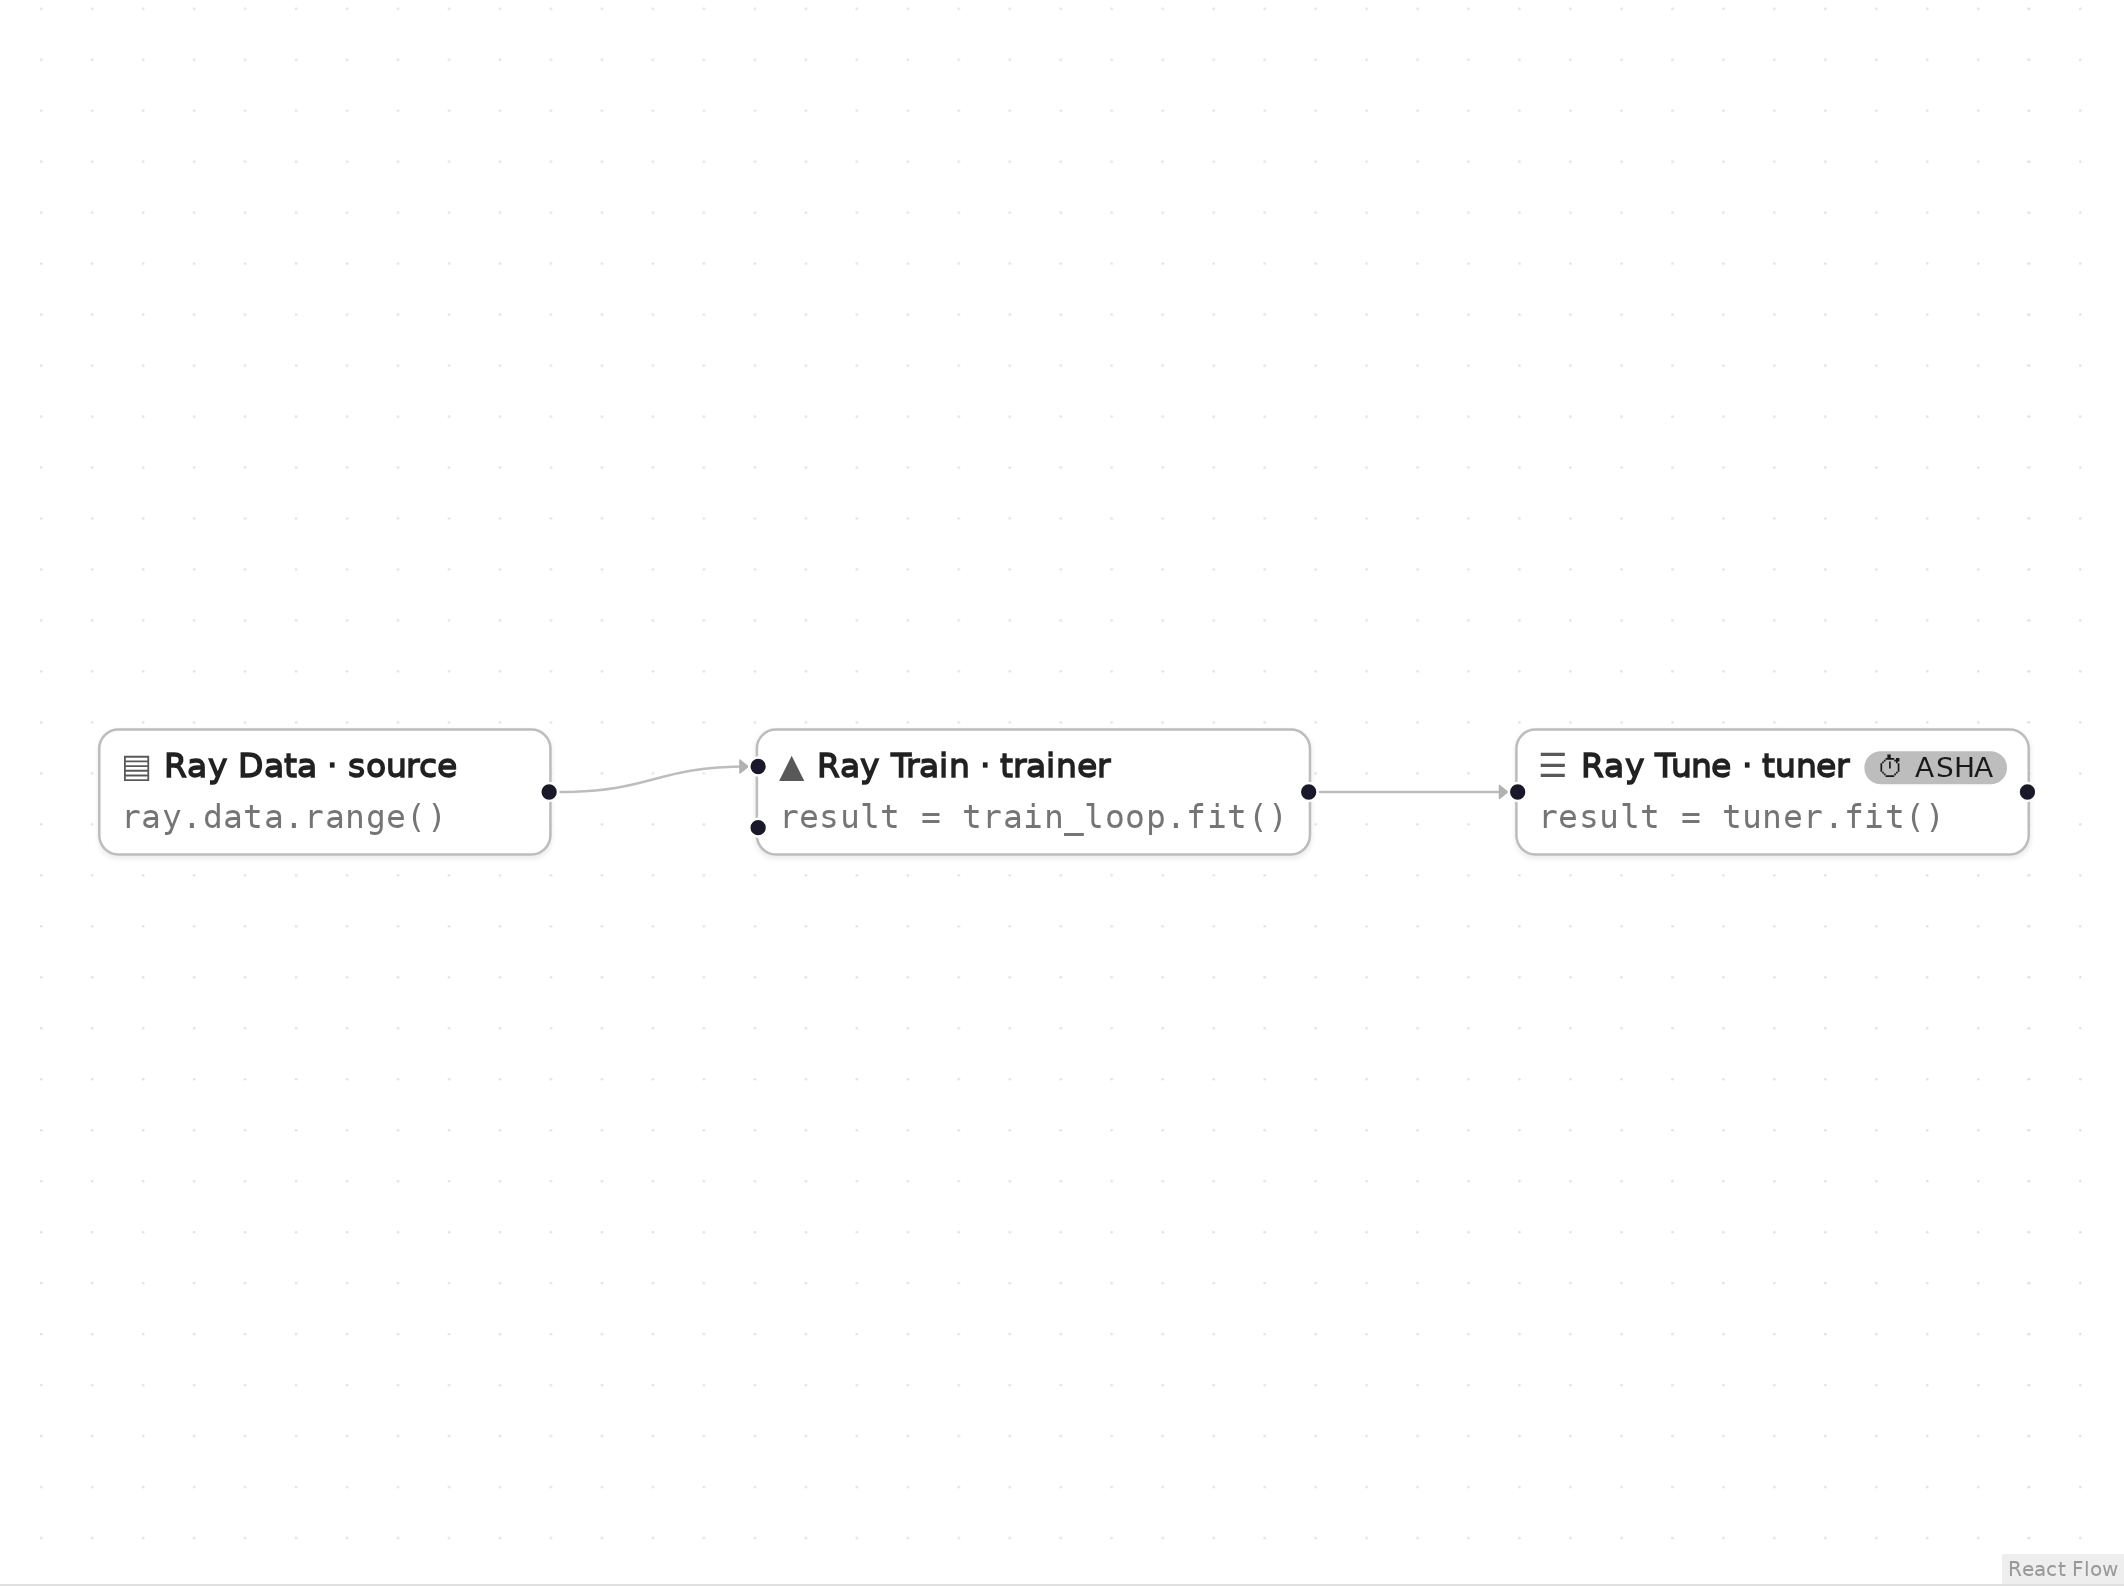

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
import ray


def train_loop(config):
    # Runs once per trial; config["lr"] is the swept value.
    lr = config["lr"]
    shard = ray.train.get_dataset_shard("train")
    for _ in shard.iter_batches(batch_size=4):
        pass
    # Report several iterations so ASHA has rungs to compare.
    for i in range(5):
        ray.train.report({"loss": float(lr) / (i + 1)})

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

from ray import tune
import ray
from ray.train import RunConfig, ScalingConfig
from ray.train.torch import TorchTrainer
from ray.tune import TuneConfig, Tuner
from ray.tune.integration.ray_train import TuneReportCallback
from ray.tune.schedulers import ASHAScheduler

if not ray.is_initialized():
    ray.init()

ds = ray.data.range(8)

def _tune_driver_n3(config):
    trainer = TorchTrainer(train_loop, train_loop_config=config["train_loop_config"], scaling_config=ScalingConfig(num_workers=1, use_gpu=False), datasets={"train": ds}, run_config=RunConfig(callbacks=[TuneReportCallback()]))
    trainer.fit()

_tuner_n3 = Tuner(_tune_driver_n3, param_space={"train_loop_config": {"lr": tune.grid_search([0.01, 0.1])}}, tune_config=TuneConfig(num_samples=1, metric="loss", mode="min", max_concurrent_trials=1, scheduler=ASHAScheduler(grace_period=1, max_t=5, reduction_factor=2)))
result = _tuner_n3.fit()
best = result.get_best_result()

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert len(result) == 2, len(result)
assert all(r.error is None for r in result), [r.error for r in result]
best_lr = best.config["train_loop_config"]["lr"]
assert best_lr in (0.01, 0.1), best_lr
print("best lr =", best_lr)

best lr = 0.01


## How the graph maps to the code

Each step names a node in the picture by its label, the lines of the generated cell it produced, and what those lines do. Node ids such as `n1` are not drawn on the canvas. Where the builder names a variable after a node, the id is its suffix (for example `_tuner_n3`).

**Setup** (lines 1, 3–9 and 11–12)

```python
# Generated with Eugo's visual Ray builder
...
from ray import tune
import ray
from ray.train import RunConfig, ScalingConfig
from ray.train.torch import TorchTrainer
from ray.tune import TuneConfig, Tuner
from ray.tune.integration.ray_train import TuneReportCallback
from ray.tune.schedulers import ASHAScheduler
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 14)

```python
ds = ray.data.range(8)
```

The dataset every trial trains on.

**Tuner** (node `n3`, lines 16, 18 and 20–22)

```python
def _tune_driver_n3(config):
...
    trainer.fit()
...
_tuner_n3 = Tuner(_tune_driver_n3, param_space={"train_loop_config": {"lr": tune.grid_search([0.01, 0.1])}}, tune_config=TuneConfig(num_samples=1, metric="loss", mode="min", max_concurrent_trials=1, scheduler=ASHAScheduler(grace_period=1, max_t=5, reduction_factor=2)))
result = _tuner_n3.fit()
best = result.get_best_result()
```

Tuner(..., param_space=grid_search over lr, tune_config=TuneConfig(metric="loss", mode="min", scheduler=ASHAScheduler(...))) runs the trials; get_best_result() picks the lowest loss.

**Trainer** (node `n2`, line 17)

```python
    trainer = TorchTrainer(train_loop, train_loop_config=config["train_loop_config"], scaling_config=ScalingConfig(num_workers=1, use_gpu=False), datasets={"train": ds}, run_config=RunConfig(callbacks=[TuneReportCallback()]))
```

The trainer is moved inside a per-trial driver function, so each trial runs its own TorchTrainer with that trial's train_loop_config.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()